<a href="https://colab.research.google.com/github/devenvaghela57-cloud/traffic-sign-weather-opencv/blob/main/traffic_sign_weather_opencv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OpenCV Traffic Sign Recognition + Weather Analyzer

Classical computer vision only: **OpenCV + NumPy** (no TensorFlow, no YOLO, no scikit-learn).
Gradio is used for the web UI and matplotlib for plots.

**Pipeline**
1. **Find signs** - HSV colour masks (red / blue / yellow) -> morphology -> contours -> shape filter
2. **Recognise signs** - HOG + colour features -> PCA -> RBF SVM (43 GTSRB classes + background). Five slightly different crops vote; the vote share is the *agreement*.
3. **Weather** - hand-made image features -> RandomForest (+ optional SVM ensemble), top-3 predictions

**How to run (new session):** `Runtime > Run all`, nothing else. Cell 1 may ask for one restart on a fresh Colab runtime; if it does, restart the session and press *Run all* again.

* First run: datasets are downloaded and both models are trained (about 20-30 min on CPU), accuracy is measured and everything is backed up to Google Drive.
* Later runs: models and metrics are restored from Drive, so the notebook is ready in about 1 minute.
* To train again from scratch set `FORCE_RETRAIN = True` in Cell 1.

No GPU needed. A normal CPU runtime is enough.

| Cell | What it does |
|---|---|
| 1 | Setup + all settings |
| 2 | Restore saved models from Google Drive |
| 3 | Download datasets (only when training) |
| 4-6 | Feature code: signs, candidate detector, weather |
| 7-8 | Train sign model, train weather model (only when needed) |
| 9 | Load models, build the `analyze()` pipeline |
| 10 | End-to-end test, write `metrics.json` |
| 11 | Backup to Google Drive |
| 12 | Results dashboard (accuracy tables and charts) |
| 13 | Web UI |

## Cell 1 - Setup and settings
Checks for OpenCV 4.x (SVM / RandomForest / HOG are not available in OpenCV 5.x). All tunable settings are here.

In [1]:
# CELL 1 - Setup and settings
import sys, os, subprocess


def _cv_ok():
    try:
        import cv2
        return all([hasattr(cv2, 'ml'), hasattr(cv2.ml, 'SVM_create'), hasattr(cv2.ml, 'RTrees_create'),
                    hasattr(cv2, 'HOGDescriptor'), hasattr(cv2, 'SIFT_create')])
    except Exception:
        return False


if not _cv_ok():
    print('Installing OpenCV 4.x (OpenCV 5.x has no SVM / RandomForest / HOG)...')
    subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', 'opencv-python',
                    'opencv-contrib-python', 'opencv-python-headless'], capture_output=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'opencv-python-headless==4.10.0.84'])
    raise RuntimeError('OpenCV 4.x installed. Now click Runtime > Restart session, then Run all again.')


def _ensure(pkg, module=None):
    try:
        __import__(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], capture_output=True)


_ensure('gradio')
_ensure('kagglehub')

import glob, json, time, random, shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------- SETTINGS -------------------------------
USE_DRIVE = True            # save / restore trained models on Google Drive (Colab only)
FORCE_RETRAIN = False       # True = ignore saved models and train everything again
TUNE_SVM = True             # small C / gamma search for the sign SVM (adds about 2 min)
N_ORIG_PER_CLASS = 250      # sign training images per class (original)
N_AUG_PER_CLASS = 250       # sign training images per class (augmented copies)
N_RANDOM_NEG_IMAGES = 700   # background patches: random crops from weather photos
N_HARD_NEG_IMAGES = 800     # background patches: wrong candidates of our own detector
K_WORDS = 100               # weather: bag-of-visual-words vocabulary size
N_TREES = 200               # weather: RandomForest trees (more = slower)
N_E2E_TEST = 100            # synthetic scenes for the end-to-end test
SEED = 42
DRIVE_DIR = '/content/drive/MyDrive/traffic_opencv'
# -------------------------------------------------------------------------

IN_COLAB = 'google.colab' in sys.modules
IMG_EXT = ('.ppm', '.png', '.jpg', '.jpeg', '.bmp', '.webp')
random.seed(SEED)
np.random.seed(SEED)
METRICS = {}


def show(images, titles=None, cols=4, size=3.2):
    """Show a grid of BGR / grayscale images."""
    n = len(images)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis('off')
        if i < n:
            im = images[i]
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap=None if im.ndim == 3 else 'gray')
            if titles is not None:
                ax.set_title(str(titles[i]), fontsize=9)
    plt.tight_layout()
    plt.show()


print('OpenCV', cv2.__version__, '| numpy', np.__version__, '| Colab:', IN_COLAB)

OpenCV 4.10.0 | numpy 2.1.3 | Colab: True


## Cell 2 - Restore saved models
If models and `metrics.json` exist on Google Drive they are restored and training is skipped. Otherwise `NEED_TRAIN` becomes `True`.

In [2]:
# CELL 2 - Restore saved models (Google Drive) and decide whether training is needed
REQUIRED_FILES = ['sign_svm.xml', 'sign_pre.npz', 'weather_rf.xml', 'weather_meta.json', 'metrics.json']
OPTIONAL_FILES = ['weather_svm.xml', 'weather_pre.npz', 'weather_bovw.npy']      # only for the v2 weather model

if USE_DRIVE and IN_COLAB:
    import os, shutil, subprocess
    # Force-unmount and clean up any stale or locked directory state
    if os.path.exists('/content/drive'):
        subprocess.run(['umount', '-l', '/content/drive'], capture_output=True)
        try:
            shutil.rmtree('/content/drive')
        except Exception:
            pass

    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    os.makedirs(DRIVE_DIR, exist_ok=True)
    if not FORCE_RETRAIN:
        for f in REQUIRED_FILES + OPTIONAL_FILES:
            src = os.path.join(DRIVE_DIR, f)
            if os.path.exists(src):
                shutil.copy(src, f)
                print('restored', f)

missing = [f for f in REQUIRED_FILES if not os.path.exists(f)]
NEED_TRAIN = FORCE_RETRAIN or bool(missing)
if FORCE_RETRAIN:
    print('FORCE_RETRAIN = True -> everything will be trained again.')
elif missing:
    print('Missing:', missing, '-> models will be trained now (one-time, about 20-30 min).')
else:
    print('All saved models found -> training is skipped.')

Mounted at /content/drive
FORCE_RETRAIN = True -> everything will be trained again.


## Cell 3 - Datasets (only when training)
GTSRB (43 sign classes) from the Kaggle mirror, with the original server as a fallback, plus the Kaggle weather dataset (11 classes).

In [3]:
# CELL 3 - Datasets (skipped when saved models are used)
SIGN_CLASS_DIRS = {}      # class id -> folder with that sign's images
WEATHER_FILES = []        # list of (image path, class name)
WEATHER_DIR = None

if not NEED_TRAIN:
    print('Saved models found -> dataset download skipped.')
else:
    import kagglehub

    def _find_class_root(root):
        """Folder that holds the 43 class sub-folders (named 0..42 or 00000..00042)."""
        for dp, dirs, _ in os.walk(root):
            if sum(d.isdigit() for d in dirs) >= 43:
                return dp
        return None

    def _download_gtsrb():
        root = _find_class_root('GTSRB')                          # already downloaded earlier in this session
        if root:
            return root
        try:                                                      # 1) Kaggle mirror (fast and reliable)
            root = _find_class_root(kagglehub.dataset_download('meowmeowmeowmeowmeow/gtsrb-german-traffic-sign'))
            if root:
                return root
        except Exception as e:
            print('Kaggle GTSRB download failed:', e)
        print('Trying the original GTSRB server...')               # 2) original benchmark server (.ppm)
        url = ('https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/'
               'GTSRB_Final_Training_Images.zip')
        subprocess.run(['wget', '-q', '--timeout=60', '--tries=2', url, '-O', 'gtsrb.zip'])
        subprocess.run(['unzip', '-q', '-o', 'gtsrb.zip'])
        if os.path.exists('gtsrb.zip'):
            os.remove('gtsrb.zip')
        return _find_class_root('GTSRB')

    GTSRB_ROOT = _download_gtsrb()
    if not GTSRB_ROOT:
        raise RuntimeError('GTSRB could not be downloaded. Upload the GTSRB training images manually '
                           '(a folder with 43 class sub-folders) into a folder named GTSRB and run again.')
    for d in sorted(os.listdir(GTSRB_ROOT)):
        if d.isdigit() and os.path.isdir(os.path.join(GTSRB_ROOT, d)):
            SIGN_CLASS_DIRS[int(d)] = os.path.join(GTSRB_ROOT, d)
    assert sorted(SIGN_CLASS_DIRS) == list(range(43)), 'GTSRB needs exactly the classes 0..42'
    n_sign_imgs = sum(len([f for f in os.listdir(p) if f.lower().endswith(IMG_EXT)]) for p in SIGN_CLASS_DIRS.values())
    print('GTSRB: classes =', len(SIGN_CLASS_DIRS), '| images =', n_sign_imgs)

    WEATHER_DIR = kagglehub.dataset_download('jehanbhathena/weather-dataset')
    if 'dataset' in os.listdir(WEATHER_DIR):
        WEATHER_DIR = os.path.join(WEATHER_DIR, 'dataset')
    WEATHER_FILES = [(f, os.path.basename(os.path.dirname(f)))
                     for f in sorted(glob.glob(os.path.join(WEATHER_DIR, '*', '*')))
                     if f.lower().endswith(IMG_EXT)]
    print('\nWeather classes:')
    for c in sorted({c for _, c in WEATHER_FILES}):
        print(f'  {c:10s}', sum(1 for _, k in WEATHER_FILES if k == c))

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
GTSRB: classes = 43 | images = 39209
Using Colab cache for faster access to the 'weather-dataset' dataset.

Weather classes:
  dew        698
  fogsmog    851
  frost      475
  glaze      639
  hail       591
  lightning  377
  rain       526
  rainbow    232
  rime       1160
  sandstorm  692
  snow       621


## Cell 4 - Sign features and augmentation
Every sign crop becomes 2020 numbers: HOG of the CLAHE-equalised gray image (1764) + red / blue / yellow / white colour maps on an 8x8 grid (256). Augmentation imitates real roads: tilt, zoom, shift, light, colour cast, fog, blur, noise and snow-like blobs. No flipping, because *turn left* and *turn right* would swap.

Features per sign crop: 2020


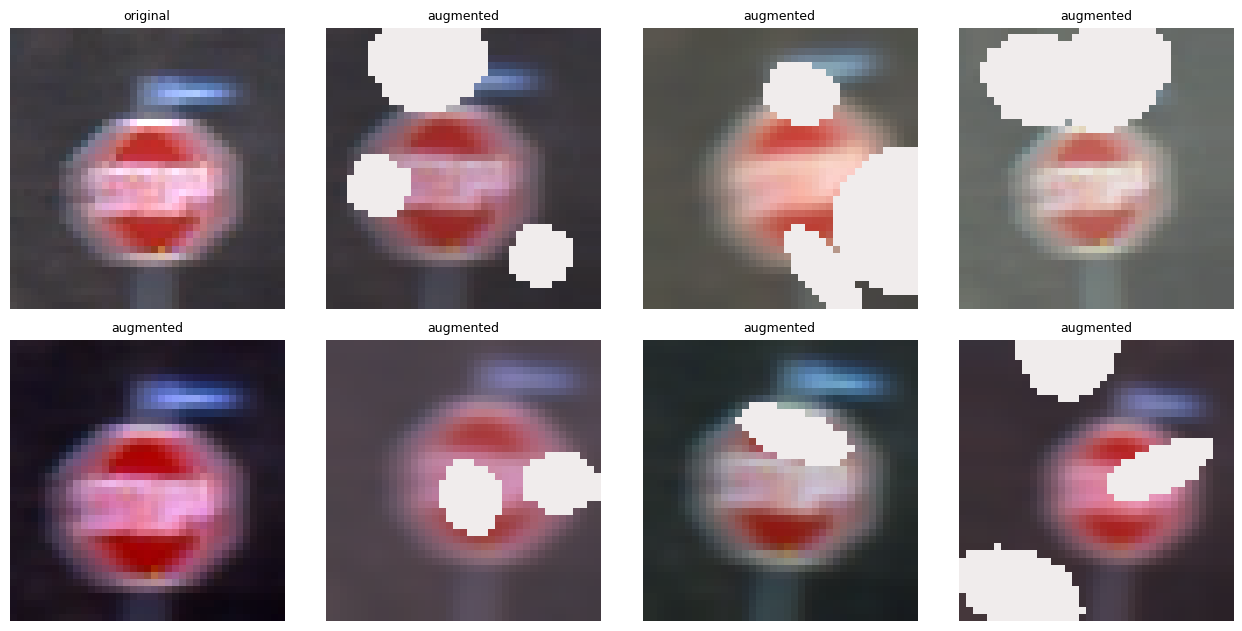

In [4]:
# CELL 4 - Sign features, augmentation, class names
SIZE = 64
GRID = 8
hog = cv2.HOGDescriptor((SIZE, SIZE), (16, 16), (8, 8), (8, 8), 9)      # 1764 numbers (shape / edges)
clahe4 = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
BG_ID = 43                                                              # 44th class = "no sign"

sign_names = {
    0: 'Speed limit (20km/h)', 1: 'Speed limit (30km/h)', 2: 'Speed limit (50km/h)',
    3: 'Speed limit (60km/h)', 4: 'Speed limit (70km/h)', 5: 'Speed limit (80km/h)',
    6: 'End of speed limit (80km/h)', 7: 'Speed limit (100km/h)', 8: 'Speed limit (120km/h)',
    9: 'No passing', 10: 'No passing veh over 3.5 tons', 11: 'Right-of-way at intersection',
    12: 'Priority road', 13: 'Yield', 14: 'Stop', 15: 'No vehicles',
    16: 'Veh > 3.5 tons prohibited', 17: 'No entry', 18: 'General caution',
    19: 'Dangerous curve left', 20: 'Dangerous curve right', 21: 'Double curve',
    22: 'Bumpy road', 23: 'Slippery road', 24: 'Road narrows on the right',
    25: 'Road work', 26: 'Traffic signals', 27: 'Pedestrians', 28: 'Children crossing',
    29: 'Bicycles crossing', 30: 'Beware of ice/snow', 31: 'Wild animals crossing',
    32: 'End speed + passing limits', 33: 'Turn right ahead', 34: 'Turn left ahead',
    35: 'Ahead only', 36: 'Go straight or right', 37: 'Go straight or left',
    38: 'Keep right', 39: 'Keep left', 40: 'Roundabout mandatory',
    41: 'End of no passing', 42: 'End no passing veh > 3.5 tons', 43: 'background',
}


def list_images(folder):
    return sorted(f for f in glob.glob(os.path.join(folder, '*')) if f.lower().endswith(IMG_EXT))


def track_id(path):
    """GTSRB: one physical sign = one 'track' of about 30 frames. Works for both file name styles:
    original  <track>_<frame>.ppm   and Kaggle  <class>_<track>_<frame>.png"""
    parts = os.path.splitext(os.path.basename(path))[0].split('_')
    if len(parts) >= 3:
        return parts[-2]
    if len(parts) == 2:
        return parts[0]
    return parts[0]


def colour_maps(img):
    """Red / blue / yellow / white masks shrunk to an 8x8 grid of fractions (256 numbers)."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    red = ((h < 10) | (h > 170)) & (s > 80) & (v > 50)
    blue = (h > 100) & (h < 130) & (s > 90) & (v > 40)
    yellow = (h > 15) & (h < 35) & (s > 90) & (v > 80)
    white = (s < 50) & (v > 170)
    maps = [cv2.resize(m.astype(np.float32), (GRID, GRID), interpolation=cv2.INTER_AREA).ravel()
            for m in (red, blue, yellow, white)]
    return np.concatenate(maps)


def sign_features(bgr):
    """One sign crop -> 2020 numbers (HOG of CLAHE-gray + colour maps)."""
    img = cv2.resize(bgr, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    gray = clahe4.apply(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))
    return np.concatenate([hog.compute(gray).ravel(), colour_maps(img)]).astype(np.float32)


N_FEATURES = len(sign_features(np.zeros((40, 40, 3), np.uint8)))


def augment_bgr(img, rs=np.random):
    """Real-road style distortions. No flip (it would swap turn-left / turn-right)."""
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rs.uniform(-12, 12), rs.uniform(0.85, 1.15))
    M[:, 2] += rs.uniform(-0.08, 0.08, 2) * np.array([w, h])                     # shift
    out = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REPLICATE).astype(np.float32)
    out = out * rs.uniform(0.85, 1.15, 3)                                        # colour cast
    out = (out - 127) * rs.uniform(0.6, 1.4) + 127 + rs.uniform(-40, 40)         # contrast + brightness
    if rs.rand() < 0.3:                                                          # fog
        a = rs.uniform(0.1, 0.5)
        out = out * (1 - a) + 200 * a
    out = np.clip(out, 0, 255).astype(np.uint8)
    if rs.rand() < 0.4:                                                          # blur
        out = cv2.GaussianBlur(out, (3, 3), float(rs.uniform(0.5, 1.5)))
    if rs.rand() < 0.3:                                                          # noise
        out = np.clip(out + rs.normal(0, 8, out.shape), 0, 255).astype(np.uint8)
    if rs.rand() < 0.5:                                                          # snow / glare patches
        for _ in range(rs.randint(1, 4)):
            ax = int(rs.randint(max(2, w // 12), max(3, w // 4) + 1))
            ay = int(rs.randint(max(2, h // 12), max(3, h // 4) + 1))
            cv2.ellipse(out, (int(rs.randint(0, w)), int(rs.randint(0, h))), (ax, ay),
                        float(rs.uniform(0, 180)), 0, 360, (236, 236, 240), -1)
    return out


# Standardise -> PCA projection. mu / sd / pca_mean / eig are set by training (Cell 7) or loaded (Cell 9).
mu = sd = pca_mean = eig = None


def project(X):
    return (((np.asarray(X, np.float32) - mu) / sd - pca_mean) @ eig.T).astype(np.float32)


print('Features per sign crop:', N_FEATURES)
if NEED_TRAIN and 14 in SIGN_CLASS_DIRS:                                          # class 14 = Stop
    _files = list_images(SIGN_CLASS_DIRS[14])
    _demo = cv2.imread(_files[len(_files) // 2])
    _r = np.random.RandomState(1)
    show([_demo] + [augment_bgr(_demo, _r) for _ in range(7)], ['original'] + ['augmented'] * 7, cols=4)

## Cell 5 - Sign candidates (colour + shape)
Separate red / blue / yellow masks (so a yellow desert background never merges with a blue sign) -> morphology -> contours -> size, aspect-ratio, solidity and convexity checks -> overlapping boxes removed.

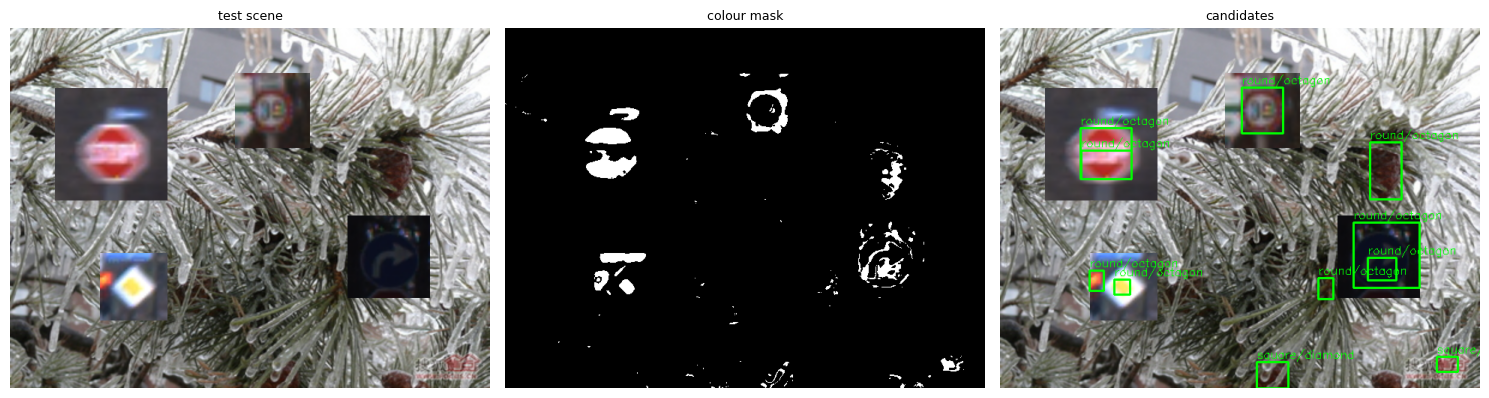

In [5]:
# CELL 5 - Sign candidates: colour + shape, OpenCV only
COLOR_RANGES = {
    'red':    [((0, 80, 50), (10, 255, 255)), ((170, 80, 50), (180, 255, 255))],
    'blue':   [((100, 100, 50), (130, 255, 255))],
    'yellow': [((15, 100, 100), (35, 255, 255))],
}
COLOR_RANGES_RELAXED = {                    # for fog / faded colours: lower saturation limits
    'red':    [((0, 45, 40), (10, 255, 255)), ((170, 45, 40), (180, 255, 255))],
    'blue':   [((100, 60, 40), (130, 255, 255))],
    'yellow': [((15, 70, 90), (35, 255, 255))],
}
clahe_v = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
MAX_SIDE = 1000


def colour_masks(bgr, relaxed=False):
    """Separate red / blue / yellow masks (dict)."""
    blur = cv2.GaussianBlur(bgr, (5, 5), 0)
    hsv = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)
    hsv[..., 2] = clahe_v.apply(np.ascontiguousarray(hsv[..., 2]))          # even out the lighting
    out = {}
    for name, ranges in (COLOR_RANGES_RELAXED if relaxed else COLOR_RANGES).items():
        m = np.zeros(hsv.shape[:2], np.uint8)
        for lo, hi in ranges:
            m |= cv2.inRange(hsv, np.array(lo, np.uint8), np.array(hi, np.uint8))
        out[name] = m
    return out


def colour_mask(bgr):
    """All three colours together (used for display only)."""
    ms = colour_masks(bgr)
    return ms['red'] | ms['blue'] | ms['yellow']


def shape_name(cnt):
    peri = cv2.arcLength(cnt, True)
    if peri == 0:
        return 'unknown'
    n = len(cv2.approxPolyDP(cnt, 0.04 * peri, True))
    if n == 3:
        return 'triangle'
    if n == 4:
        return 'square/diamond'
    return 'round/octagon'


def box_area(b):
    return b[2] * b[3]


def box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[0] + a[2], b[0] + b[2]), min(a[1] + a[3], b[1] + b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    return inter / float(box_area(a) + box_area(b) - inter + 1e-9)


def crop_box(img, box, pad=0.10, shift=(0.0, 0.0)):
    """Square crop around a box (no stretching). pad = extra margin, shift = fraction of the box size."""
    H, W = img.shape[:2]
    x, y, w, h = box
    cx, cy = x + w / 2.0 + shift[0] * w, y + h / 2.0 + shift[1] * h
    half = max(w, h) * (1 + 2 * pad) / 2.0
    x1, y1 = int(max(0, cx - half)), int(max(0, cy - half))
    x2, y2 = int(min(W, cx + half)), int(min(H, cy + half))
    return img[y1:y2, x1:x2]


def find_candidates(bgr, max_candidates=15, relaxed=False):
    """Per colour mask: morphology -> contours -> shape checks. Returns [{'box', 'shape'}], biggest first."""
    H0, W0 = bgr.shape[:2]
    s = min(1.0, MAX_SIDE / float(max(H0, W0)))
    img = cv2.resize(bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1.0 else bgr
    H, W = img.shape[:2]

    found = []
    for mask in colour_masks(img, relaxed).values():
        for frac in (0.015, 0.05):      # small close = the sign itself; big close = joins pieces broken by snow / letters
            k = max(5, int(min(H, W) * frac)) | 1
            m = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
            m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
            cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for c in cnts:
                area = cv2.contourArea(c)
                if area < 0.0008 * H * W or area > 0.85 * H * W:        # too small, or the whole background
                    continue
                x, y, w, h = cv2.boundingRect(c)
                if min(w, h) < 16 or not (0.45 < w / float(h) < 1.8):
                    continue
                if area / float(w * h) < 0.35:                          # too thin / hollow
                    continue
                hull = cv2.contourArea(cv2.convexHull(c))
                if hull == 0 or area / hull < 0.6:                      # signs are convex
                    continue
                found.append(((x, y, w, h), shape_name(c)))

    found.sort(key=lambda t: box_area(t[0]), reverse=True)
    kept = []
    for box, shp in found:                                              # keep one of nearly identical boxes
        if all(box_iou(box, k['box']) < 0.7 for k in kept):
            kept.append({'box': box, 'shape': shp})
    out = []
    for k in kept[:max_candidates]:                                     # back to original image coordinates
        x, y, w, h = k['box']
        out.append({'box': (int(x / s), int(y / s), int(w / s), int(h / s)), 'shape': k['shape']})
    return out


# ---- demo: paste GTSRB signs on a weather photo and look at the candidates ----
if NEED_TRAIN and WEATHER_FILES:
    def _first_sign(cid):
        fs = list_images(SIGN_CLASS_DIRS[cid])
        return cv2.imread(fs[len(fs) // 2])

    _bg = cv2.resize(cv2.imread(WEATHER_FILES[len(WEATHER_FILES) // 3][0]), (640, 480))
    _scene = _bg.copy()
    for cid, size, (px, py) in [(14, 150, (60, 80)), (1, 100, (300, 60)), (33, 110, (450, 250)), (12, 90, (120, 300))]:
        _scene[py:py + size, px:px + size] = cv2.resize(_first_sign(cid), (size, size))
    _vis = _scene.copy()
    for c in find_candidates(_scene):
        x, y, w, h = c['box']
        cv2.rectangle(_vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(_vis, c['shape'], (x, max(15, y - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    show([_scene, colour_mask(_scene), _vis], ['test scene', 'colour mask', 'candidates'], cols=3, size=5)

## Cell 6 - Weather features
Hand-made measurements: brightness and contrast, saturation, haze (dark channel), Gabor / LBP texture, HOG, FFT sharpness, Hough lines (rain, lightning), bright and dark spots, sky colour, rainbow hues and a SIFT bag-of-visual-words.
**v1** = 132 basic numbers, **v2** = v1 + about 280 extra numbers + vocabulary. Cell 8 trains both and keeps the better one.

In [6]:
# CELL 6 - Weather features, OpenCV + NumPy only
GABOR_KERNELS = [cv2.getGaborKernel((11, 11), 2.5, th, lam, 0.5, 0, ktype=cv2.CV_32F)
                 for th in (0, np.pi / 4, np.pi / 2, 3 * np.pi / 4) for lam in (4.0, 8.0)]


def weather_features_v1(bgr):
    """132 basic numbers: light, contrast, saturation, hue, layout, edges, haze, texture, sky, colour cast."""
    img = cv2.resize(bgr, (160, 160), interpolation=cv2.INTER_AREA)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB).astype(np.float32) / 255.0
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h = hsv[..., 0].astype(np.float32)
    s = hsv[..., 1].astype(np.float32) / 255.0
    v = hsv[..., 2].astype(np.float32) / 255.0
    g = gray.astype(np.float32) / 255.0
    f = []
    # 1) brightness + contrast
    f += [g.mean(), g.std()] + list(np.percentile(g, [5, 25, 50, 75, 95]))
    f += [(g > 0.78).mean(), (g > 0.92).mean(), (g < 0.2).mean()]
    # 2) saturation
    f += [s.mean(), s.std(), (s < 0.15).mean(), (s > 0.6).mean()]
    # 3) hue distribution (12 bins, coloured pixels only)
    f += list(np.histogram(h[s > 0.25], bins=12, range=(0, 180))[0] / float(h.size))
    # 4) rainbow: how many different hue bins are strongly saturated
    strong = (s > 0.5) & (v > 0.5)
    hb = np.histogram(h[strong], bins=12, range=(0, 180))[0] / float(h.size)
    f += [(hb > 0.004).sum() / 12.0]
    # 5) 3x3 layout: brightness and saturation per cell (sky vs ground)
    for arr in (v, s):
        f += list(cv2.resize(arr, (3, 3), interpolation=cv2.INTER_AREA).ravel())
    # 6) edges, sharpness, gradient direction
    edges = cv2.Canny(gray, 80, 160)
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1)
    ax, ay = float(np.abs(gx).mean()), float(np.abs(gy).mean())
    f += [(edges > 0).mean(), np.log1p(cv2.Laplacian(g, cv2.CV_32F).var() * 1000), ax, ay, ay / (ax + 1e-6)]
    # 7) haze / fog: dark channel
    dark = cv2.erode(img.min(axis=2), np.ones((9, 9), np.uint8)).astype(np.float32) / 255.0
    f += [dark.mean(), (dark > 0.5).mean()]
    # 8) texture: Gabor energy (frost / dew / rime / glaze / rain)
    small = cv2.resize(g, (80, 80), interpolation=cv2.INTER_AREA)
    f += [float(np.abs(cv2.filter2D(small, cv2.CV_32F, k)).mean()) for k in GABOR_KERNELS]
    # 9) sandstorm (orange / brown), sky blue (top third), lightning (bright flash in a dark scene)
    f += [(((h > 8) & (h < 25)) & (s > 0.3)).mean()]
    top = slice(0, 53)
    f += [(((h[top] > 95) & (h[top] < 130)) & (s[top] > 0.2)).mean(), v[top].mean()]
    f += [(v > 0.97).mean() * (1.0 - g.mean())]
    # 10) Lab colour cast
    f += [lab[..., 1].mean(), lab[..., 1].std(), lab[..., 2].mean(), lab[..., 2].std()]
    # 11) coarse HSV histogram 4x4x4
    ch = cv2.calcHist([hsv], [0, 1, 2], None, [4, 4, 4], [0, 180, 0, 256, 0, 256]).ravel()
    f += list(ch / ch.sum())
    return np.array(f, np.float32)


# ======================= v2: stronger features =======================
def _build_lbp_lut():
    lut = np.zeros(256, np.uint8)
    for code_ in range(256):
        bits = [(code_ >> k) & 1 for k in range(8)]
        trans = sum(bits[k] != bits[(k + 1) % 8] for k in range(8))
        lut[code_] = sum(bits) if trans <= 2 else 9            # rotation-invariant uniform LBP: 10 bins
    return lut


LBP_LUT = _build_lbp_lut()
_NEIGH = [(-1, -1), (-1, 0), (-1, 1), (0, 1), (1, 1), (1, 0), (1, -1), (0, -1)]


def lbp_features(gray):
    g = gray.astype(np.int16)
    H, W = g.shape
    c = g[1:-1, 1:-1]
    codes = np.zeros(c.shape, np.uint8)
    for k, (dy, dx) in enumerate(_NEIGH):
        codes |= ((g[1 + dy:H - 1 + dy, 1 + dx:W - 1 + dx] >= c).astype(np.uint8) << k)
    lbp = LBP_LUT[codes]
    h, w = lbp.shape
    out = [np.bincount(lbp.ravel(), minlength=10) / float(lbp.size)]
    for i in range(2):
        for j in range(2):
            cell = lbp[i * h // 2:(i + 1) * h // 2, j * w // 2:(j + 1) * w // 2]
            out.append(np.bincount(cell.ravel(), minlength=10) / float(cell.size))
    return np.concatenate(out)                                  # 50 numbers


_hog_w = cv2.HOGDescriptor((64, 64), (32, 32), (32, 32), (16, 16), 9)             # 144 numbers
_yy, _xx = np.mgrid[-32:32, -32:32]
_RING = np.minimum((np.hypot(_yy, _xx) / 32.0 * 8).astype(int), 7)
_K7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))


def fft_features(g64):
    """Energy per frequency ring: blur / fog (low frequencies) vs fine texture (high frequencies)."""
    a = g64.astype(np.float32) / 255.0
    f = np.fft.fftshift(np.abs(np.fft.fft2(a - a.mean())))
    e = np.bincount(_RING.ravel(), weights=(f ** 2).ravel(), minlength=8)
    e = e / (e.sum() + 1e-9)
    return np.concatenate([e, [e[4:].sum() / (e[:2].sum() + 1e-6)]])                # 9 numbers


def line_features(gray):
    """Hough lines: count, mean length, direction histogram (rain streaks, lightning)."""
    lines = cv2.HoughLinesP(cv2.Canny(gray, 60, 150), 1, np.pi / 180, 30, minLineLength=20, maxLineGap=3)
    if lines is None:
        return np.zeros(8, np.float64)
    l = lines.reshape(-1, 4).astype(np.float32)
    dx, dy = l[:, 2] - l[:, 0], l[:, 3] - l[:, 1]
    length = np.hypot(dx, dy)
    ang = np.mod(np.arctan2(dy, dx), np.pi)
    hist = np.bincount(np.minimum((ang / np.pi * 6).astype(int), 5), weights=length, minlength=6)
    hist = hist / (hist.sum() + 1e-6)
    return np.concatenate([[min(len(l), 100) / 100.0, length.mean() / 128.0], hist])  # 8 numbers


def spot_features(gray):
    """Small bright spots (dew, hail, snowfall) and small dark spots."""
    th = cv2.morphologyEx(gray, cv2.MORPH_TOPHAT, _K7)
    bh = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, _K7)
    return np.array([th.mean() / 255.0, (th > 30).mean(), bh.mean() / 255.0, (bh > 30).mean()])


# ---- Bag of Visual Words (RootSIFT + k-means vocabulary; the vocabulary is built in Cell 8) ----
sift = cv2.SIFT_create(nfeatures=150)
bovw_centers = None


def sift_descriptors(bgr):
    g = cv2.cvtColor(cv2.resize(bgr, (160, 160), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)
    _, d = sift.detectAndCompute(g, None)
    if d is None or len(d) == 0:
        return np.zeros((0, 128), np.float32)
    d = d / (np.abs(d).sum(1, keepdims=True) + 1e-7)
    return np.sqrt(d).astype(np.float32)


def bovw_vector(bgr):
    if bovw_centers is None:
        return np.zeros(0, np.float32)
    K = len(bovw_centers)
    d = sift_descriptors(bgr)
    if len(d) == 0:
        return np.zeros(K, np.float32)
    dist = (d ** 2).sum(1, keepdims=True) - 2 * d @ bovw_centers.T + (bovw_centers ** 2).sum(1)[None]
    h = np.bincount(dist.argmin(1), minlength=K).astype(np.float32)
    return np.sqrt(h / (h.sum() + 1e-9))


def weather_features_v2(bgr, bv=None):
    """v1 (132) + Lab histogram (64) + LBP (50) + HOG (144) + FFT (9) + lines (8) + spots (4) + BoVW (K)."""
    base = weather_features_v1(bgr)
    img = cv2.resize(bgr, (128, 128), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    lab_h = cv2.calcHist([cv2.cvtColor(img, cv2.COLOR_BGR2LAB)], [1, 2], None, [8, 8], [0, 256, 0, 256]).ravel()
    lab_h = lab_h / (lab_h.sum() + 1e-9)
    g96 = cv2.resize(gray, (96, 96), interpolation=cv2.INTER_AREA)
    g64 = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA)
    if bv is None:
        bv = bovw_vector(bgr)
    return np.concatenate([base, lab_h, lbp_features(g96), _hog_w.compute(g64).ravel(), fft_features(g64),
                           line_features(gray), spot_features(gray), bv]).astype(np.float32)


def rf_probs(rf, X, n_classes):
    """RandomForest votes -> per-class probability (votes / trees)."""
    v = rf.getVotes(np.asarray(X, np.float32), 0)
    classes = v[0].astype(int)
    counts = v[1:].astype(np.float32)
    P = np.zeros((len(X), n_classes), np.float32)
    P[:, classes] = counts / np.maximum(counts.sum(1, keepdims=True), 1)
    return P


# Weather SVM (v2 only): Standardise -> PCA -> RBF SVM. Values are set by Cell 8 (training) or Cell 9 (loading).
w_mu = w_sd = w_pm = w_eig = None
weather_svm = None


def w_project(X):
    return (((np.asarray(X, np.float32) - w_mu) / w_sd - w_pm) @ w_eig.T).astype(np.float32)


def weather_svm_onehot(svm_model, X, n_classes):
    lab = svm_model.predict(w_project(X))[1].ravel().astype(int)
    P = np.zeros((len(X), n_classes), np.float32)
    P[np.arange(len(X)), lab] = 1.0
    return P


W_N_V1 = len(weather_features_v1(np.zeros((100, 100, 3), np.uint8)))
W_N_V2_BASE = len(weather_features_v2(np.zeros((100, 100, 3), np.uint8)))
print('Weather features: v1 = %d | v2 (without BoVW) = %d' % (W_N_V1, W_N_V2_BASE))

Weather features: v1 = 132 | v2 (without BoVW) = 411


## Cell 7 - Train the sign classifier (only when needed, about 5 min)
GTSRB is split **track-wise**: all frames of one physical sign stay on the same side, so the validation accuracy is honest (a random split would put near-identical frames in both sets). Training data = original + augmented crops + a background class (random weather-photo patches and hard negatives from our own detector). Pipeline: standardise -> PCA (150) -> RBF SVM with a small C / gamma search.

In [7]:
# CELL 7 - Sign classifier: data -> PCA -> SVM -> honest evaluation
if not NEED_TRAIN:
    print('Skipped: the saved sign model is loaded in Cell 9.')
else:
    rs = np.random.RandomState(SEED)

    # --- A) track-wise split of GTSRB ---
    train_items, val_items = [], []
    for cid, cdir in sorted(SIGN_CLASS_DIRS.items()):
        tracks = {}
        for f in list_images(cdir):
            tracks.setdefault(track_id(f), []).append(f)
        tids = sorted(tracks)
        rs.shuffle(tids)
        n_val = max(1, int(round(0.2 * len(tids))))
        train_items += [(f, cid) for t in tids[n_val:] for f in tracks[t]]
        val_items += [(f, cid) for t in tids[:n_val] for f in tracks[t]]
    print('GTSRB split -> train images:', len(train_items), '| val images:', len(val_items))

    def sample_per_class(items, n):
        by = {}
        for f, c in items:
            by.setdefault(c, []).append(f)
        out = []
        for c in sorted(by):
            fs = by[c]
            out += [(fs[i], c) for i in rs.permutation(len(fs))[:n]]
        return out

    def feats_from_items(items, augment=False):
        X, y = [], []
        for f, c in items:
            img = cv2.imread(f)
            if img is None:
                continue
            if augment:
                img = augment_bgr(img, rs)
            X.append(sign_features(img))
            y.append(c)
        return np.array(X, np.float32), np.array(y, np.int32)

    t0 = time.time()
    Xo, yo = feats_from_items(sample_per_class(train_items, N_ORIG_PER_CLASS))
    Xa, ya = feats_from_items(sample_per_class(train_items, N_AUG_PER_CLASS), augment=True)
    val_sample = sample_per_class(val_items, 100)
    Xv, yv = feats_from_items(val_sample)                          # clean validation
    Xvs, yvs = feats_from_items(val_sample, augment=True)          # stress validation (augmented)
    print('Signs ready: train', len(Xo) + len(Xa), '| val clean', len(Xv), '| val stress', len(Xvs),
          '| %.0fs' % (time.time() - t0))

    # --- B) background class (weather photos contain no traffic signs) ---
    wf = [f for f, _ in WEATHER_FILES]
    rs.shuffle(wf)
    half = len(wf) // 2
    neg = []
    for f in wf[:min(N_RANDOM_NEG_IMAGES, half)]:                  # (i) random patches
        img = cv2.imread(f)
        if img is None:
            continue
        H, W = img.shape[:2]
        for _ in range(2):
            side = max(12, int(rs.uniform(0.15, 0.6) * min(H, W)))
            x, y = rs.randint(0, max(1, W - side + 1)), rs.randint(0, max(1, H - side + 1))
            neg.append(sign_features(img[y:y + side, x:x + side]))
    n_random = len(neg)
    for f in wf[half:half + N_HARD_NEG_IMAGES]:                    # (ii) hard negatives: our own detector's wrong boxes
        img = cv2.imread(f)
        if img is None:
            continue
        for c in find_candidates(img, max_candidates=4):
            crop = crop_box(img, c['box'], 0.10)
            if crop.size:
                neg.append(sign_features(crop))
    neg = np.array(neg, np.float32)
    print('Background crops:', len(neg), f'(random {n_random}, hard {len(neg) - n_random})')
    perm = rs.permutation(len(neg))
    n_nv = int(0.15 * len(neg))
    X_bg_val, X_bg_tr = neg[perm[:n_nv]], neg[perm[n_nv:]]

    X_train = np.concatenate([Xo, Xa, X_bg_tr])
    y_train = np.concatenate([yo, ya, np.full(len(X_bg_tr), BG_ID, np.int32)])
    print('X_train:', X_train.shape, '| classes:', len(np.unique(y_train)))

    # --- C) standardise -> PCA ---
    N_PCA = 150
    mu = X_train.mean(0)
    sd = X_train.std(0) + 1e-6
    Z = (X_train - mu) / sd
    pca_mean = Z.mean(0, keepdims=True)
    Zc = Z - pca_mean
    cov = (Zc.T @ Zc).astype(np.float64) / (len(Zc) - 1)
    evals, evecs = np.linalg.eigh(cov)
    order = np.argsort(evals)[::-1][:N_PCA]
    eig = evecs[:, order].T.astype(np.float32)
    pca_var = 100 * evals[order].sum() / evals.sum()
    print('PCA: %d -> %d dims, variance kept: %.1f%%' % (Z.shape[1], N_PCA, pca_var))
    del Z, Zc, cov

    # --- D) RBF SVM (small C / gamma search, scored on clean + stress validation) ---
    def make_svm(C, gamma):
        m = cv2.ml.SVM_create()
        m.setType(cv2.ml.SVM_C_SVC)
        m.setKernel(cv2.ml.SVM_RBF)
        m.setC(C)
        m.setGamma(gamma)
        m.setTermCriteria((cv2.TERM_CRITERIA_MAX_ITER, 1000, 1e-6))
        return m

    P_tr, P_v, P_vs, P_bg = project(X_train), project(Xv), project(Xvs), project(X_bg_val)
    base_gamma = 1.0 / float(P_tr.var(0).sum())
    grid = [(C, g) for C in (10.0, 30.0) for g in (0.5, 1.0, 2.0)] if TUNE_SVM else [(10.0, 1.0)]
    print('\nSVM search (C, gamma multiplier) ->', len(grid), 'models')
    best = None
    for C, gm in grid:
        t0 = time.time()
        m = make_svm(C, base_gamma * gm)
        m.train(P_tr, cv2.ml.ROW_SAMPLE, y_train.reshape(-1, 1))
        a_clean = float((m.predict(P_v)[1].ravel().astype(int) == yv).mean())
        a_stress = float((m.predict(P_vs)[1].ravel().astype(int) == yvs).mean())
        print('  C=%-5g gamma x%-4g | clean %.2f%% | stress %.2f%% | %.0fs' % (C, gm, 100 * a_clean, 100 * a_stress, time.time() - t0))
        score = (a_clean + a_stress) / 2
        if best is None or score > best[0]:
            best = (score, C, gm, m)
    _, C_best, g_best, sign_svm_new = best
    print('Chosen: C=%g, gamma x%g' % (C_best, g_best))

    # --- E) honest evaluation (validation tracks were never seen in training) ---
    pv = sign_svm_new.predict(P_v)[1].ravel().astype(int)
    pvs = sign_svm_new.predict(P_vs)[1].ravel().astype(int)
    pbg = sign_svm_new.predict(P_bg)[1].ravel().astype(int)
    cm = np.zeros((44, 44), int)
    for t, p in zip(yv, pv):
        cm[t, p] += 1
    per_class = {int(c): float((pv[yv == c] == c).mean()) for c in np.unique(yv)}
    METRICS['sign'] = {
        'clean_acc': float((pv == yv).mean()), 'stress_acc': float((pvs == yvs).mean()),
        'bg_false_sign': float((pbg != BG_ID).mean()), 'sign_as_bg': float((pv == BG_ID).mean()),
        'per_class_acc': per_class, 'confusion': cm.tolist(),
        'n_train': int(len(X_train)), 'n_val_clean': int(len(yv)), 'n_val_stress': int(len(yvs)),
        'pca_dims': N_PCA, 'pca_variance_pct': float(pca_var), 'svm_C': C_best, 'svm_gamma_mult': g_best,
    }
    S = METRICS['sign']
    print('\nVal accuracy (clean)            : %.2f%%' % (100 * S['clean_acc']))
    print('Val accuracy (stress/augmented) : %.2f%%' % (100 * S['stress_acc']))
    print('Background wrongly called a sign: %.2f%%   (lower is better)' % (100 * S['bg_false_sign']))
    print('Sign wrongly called background  : %.2f%%   (lower is better)' % (100 * S['sign_as_bg']))
    print('(C and gamma were chosen on this validation set, so the numbers can be slightly optimistic.)')
    weakest = sorted(per_class.items(), key=lambda t: t[1])[:5]
    print('Weakest 5 classes:', ', '.join('%d %s (%.0f%%)' % (c, sign_names[c], 100 * a) for c, a in weakest))

    sign_svm_new.save('sign_svm.xml')
    np.savez('sign_pre.npz', mu=mu, sd=sd, pca_mean=pca_mean, eig=eig)
    print('Saved: sign_svm.xml, sign_pre.npz')
    del X_train, P_tr, Xo, Xa

GTSRB split -> train images: 31379 | val images: 7830
Signs ready: train 20340 | val clean 3620 | val stress 3620 | 152s
Background crops: 2694 (random 1400, hard 1294)
X_train: (22630, 2020) | classes: 44
PCA: 2020 -> 150 dims, variance kept: 73.6%

SVM search (C, gamma multiplier) -> 6 models
  C=10    gamma x0.5  | clean 90.75% | stress 58.56% | 38s
  C=10    gamma x1    | clean 90.41% | stress 59.70% | 49s
  C=10    gamma x2    | clean 88.95% | stress 56.69% | 77s
  C=30    gamma x0.5  | clean 89.83% | stress 58.20% | 36s
  C=30    gamma x1    | clean 90.33% | stress 59.48% | 48s
  C=30    gamma x2    | clean 88.95% | stress 56.71% | 80s
Chosen: C=10, gamma x1

Val accuracy (clean)            : 90.41%
Val accuracy (stress/augmented) : 59.70%
Background wrongly called a sign: 4.46%   (lower is better)
Sign wrongly called background  : 0.55%   (lower is better)
(C and gamma were chosen on this validation set, so the numbers can be slightly optimistic.)
Weakest 5 classes: 27 Pedestria

## Cell 8 - Train the weather classifier (only when needed, about 10-20 min)
Four candidates are trained and compared on the **same** validation images; the best one is saved:
**A** v1 features + RandomForest (baseline) | **B** v2 features + RandomForest | **C** v2 features + SVM | **D** B and C combined.
Small classes are repeated up to 60% of the largest class and every training image is also used flipped and randomly cropped.

In [8]:
# CELL 8 - Weather classifier: compare 4 models, save the best
if not NEED_TRAIN:
    print('Skipped: the saved weather model is loaded in Cell 9.')
else:
    MERGE = {}               # to merge similar classes use e.g. {'frost': 'ice', 'glaze': 'ice', 'rime': 'ice'}
    rs_w = np.random.RandomState(7)

    raw_classes = sorted(c for c in os.listdir(WEATHER_DIR) if os.path.isdir(os.path.join(WEATHER_DIR, c)))
    wnames = sorted(set(MERGE.get(c, c) for c in raw_classes))
    w_id = {n: i for i, n in enumerate(wnames)}
    NC = len(wnames)

    # ---- 1) split: 20% of every class goes to validation ----
    train_files, val_files = [], []
    for c in raw_classes:
        files = [f for f in sorted(glob.glob(os.path.join(WEATHER_DIR, c, '*'))) if f.lower().endswith(IMG_EXT)]
        rs_w.shuffle(files)
        n_val = int(0.2 * len(files))
        cid = w_id[MERGE.get(c, c)]
        val_files += [(f, cid) for f in files[:n_val]]
        train_files += [(f, cid) for f in files[n_val:]]
    print('Train images:', len(train_files), '| Val images:', len(val_files))

    # ---- 2) BoVW vocabulary: k-means on RootSIFT descriptors ----
    t0 = time.time()
    desc = []
    for i in rs_w.permutation(len(train_files))[:1500]:
        img = cv2.imread(train_files[i][0])
        if img is None:
            continue
        d = sift_descriptors(img)
        if len(d):
            desc.append(d[rs_w.permutation(len(d))[:60]])
    desc = np.concatenate(desc).astype(np.float32)
    K = min(K_WORDS, len(desc) // 5)
    _, _, centers = cv2.kmeans(desc, K, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 1e-3),
                               3, cv2.KMEANS_PP_CENTERS)
    bovw_centers = centers.astype(np.float32)
    print('Vocabulary: %d words from %d descriptors | %.0fs' % (K, len(desc), time.time() - t0))

    # ---- 3) features: every training image in 3 variants (original, flipped, random crop) ----
    def random_crop(img):
        h, w = img.shape[:2]
        s = rs_w.uniform(0.75, 0.95)
        ch, cw = max(8, int(h * s)), max(8, int(w * s))
        y, x = rs_w.randint(0, h - ch + 1), rs_w.randint(0, w - cw + 1)
        return img[y:y + ch, x:x + cw]

    t0 = time.time()
    Xtr, ytr, vtr = [], [], []
    for n_done, (f, cid) in enumerate(train_files, 1):
        img = cv2.imread(f)
        if img is None:
            continue
        bv = bovw_vector(img)                                      # SIFT only once per image
        for vid, im in enumerate((img, cv2.flip(img, 1), random_crop(img))):
            Xtr.append(weather_features_v2(im, bv))
            ytr.append(cid)
            vtr.append(vid)
        if n_done % 1500 == 0:
            print('  train features: %d / %d images | %.0fs' % (n_done, len(train_files), time.time() - t0))
    Xwv, ywv = [], []
    for f, cid in val_files:
        img = cv2.imread(f)
        if img is None:
            continue
        Xwv.append(weather_features_v2(img))
        ywv.append(cid)
    Xtr, ytr, vtr = np.array(Xtr, np.float32), np.array(ytr, np.int32), np.array(vtr)
    Xwv, ywv = np.array(Xwv, np.float32), np.array(ywv, np.int32)
    print('Features done: train %d x %d | val %d | %.0fs' % (len(Xtr), Xtr.shape[1], len(Xwv), time.time() - t0))

    # ---- 4) helpers ----
    def balance(X, y, frac=0.6):
        cnt = np.bincount(y, minlength=NC)
        target = int(frac * cnt.max())
        idx = [np.arange(len(y))]
        for c in range(NC):
            if 0 < cnt[c] < target:
                idx.append(rs_w.choice(np.where(y == c)[0], target - cnt[c], replace=True))
        idx = np.concatenate(idx)
        return X[idx], y[idx]

    def train_rf(X, y, trees, depth):
        rf = cv2.ml.RTrees_create()
        rf.setMaxDepth(depth)
        rf.setMinSampleCount(2)
        rf.setActiveVarCount(0)                                    # 0 = sqrt(number of features)
        rf.setTermCriteria((cv2.TERM_CRITERIA_MAX_ITER, trees, 0))
        rf.train(np.asarray(X, np.float32), cv2.ml.ROW_SAMPLE, np.asarray(y, np.int32).reshape(-1, 1))
        return rf

    def score(name, P, y):
        pred = P.argmax(1)
        acc = float((pred == y).mean())
        bal = float(np.mean([(pred[y == c] == c).mean() for c in range(NC) if (y == c).any()]))
        top3 = float(np.mean([y[i] in np.argsort(P[i])[::-1][:3] for i in range(len(y))]))
        print(f'  {name:36s} acc {acc:6.1%} | balanced {bal:6.1%} | top-3 {top3:6.1%}')
        return {'acc': acc, 'balanced': bal, 'top3': top3}

    print('\n--- Same validation images, 4 candidates ---')
    # ---- 5) A: baseline = first 132 columns (v1 features) + RF ----
    t0 = time.time()
    m_ab = vtr < 2                                                 # original + flipped only
    rf_a = train_rf(Xtr[m_ab][:, :W_N_V1], ytr[m_ab], trees=min(N_TREES, 300), depth=25)
    P_a = rf_probs(rf_a, Xwv[:, :W_N_V1], NC)
    res = {'A  v1 features + RF': score('A  v1 features + RF', P_a, ywv)}
    print('     (A trained in %.0fs)' % (time.time() - t0))

    # ---- 6) B: v2 features + class balancing + RF ----
    t0 = time.time()
    Xb, yb = balance(Xtr, ytr)
    print('  balanced training set:', len(Xb), '| per class:', np.bincount(yb, minlength=NC).tolist())
    rf_b = train_rf(Xb, yb, trees=N_TREES, depth=30)
    P_b = rf_probs(rf_b, Xwv, NC)
    res['B  v2 features + RF'] = score('B  v2 features + RF', P_b, ywv)
    print('     (B trained in %.0fs)' % (time.time() - t0))

    # ---- 7) C: v2 features + SVM (standardise -> PCA 128 -> RBF) ----
    t0 = time.time()
    w_mu = Xb.mean(0)
    w_sd = Xb.std(0) + 1e-6
    sel = np.concatenate([rs_w.permutation(np.where(yb == c)[0])[:1500] for c in range(NC)])   # cap per class: keeps the SVM fast
    Zs = (Xb[sel] - w_mu) / w_sd
    w_pm = Zs.mean(0, keepdims=True)
    cov = ((Zs - w_pm).T @ (Zs - w_pm)).astype(np.float64) / (len(Zs) - 1)
    ev, evec = np.linalg.eigh(cov)
    w_eig = evec[:, np.argsort(ev)[::-1][:128]].T.astype(np.float32)
    Pz = w_project(Xb[sel])
    w_svm = cv2.ml.SVM_create()
    w_svm.setType(cv2.ml.SVM_C_SVC)
    w_svm.setKernel(cv2.ml.SVM_RBF)
    w_svm.setC(10.0)
    w_svm.setGamma(1.0 / float(Pz.var(0).sum()))
    w_svm.setTermCriteria((cv2.TERM_CRITERIA_MAX_ITER, 1000, 1e-6))
    w_svm.train(Pz, cv2.ml.ROW_SAMPLE, yb[sel].reshape(-1, 1))
    S_va = weather_svm_onehot(w_svm, Xwv, NC)
    res['C  v2 features + SVM'] = score('C  v2 features + SVM', S_va, ywv)
    print('     (C trained in %.0fs)' % (time.time() - t0))

    # ---- 8) D: ensemble (probability = 0.5 * RF + 0.5 * SVM vote) ----
    ALPHA = 0.5
    P_d = (1 - ALPHA) * P_b + ALPHA * S_va
    res['D  RF + SVM ensemble'] = score('D  RF + SVM ensemble', P_d, ywv)

    # ---- 9) pick the best and save it (accuracy first, balanced accuracy as tie-breaker) ----
    best_name = max(res, key=lambda k: (round(res[k]['acc'], 3), round(res[k]['balanced'], 3), res[k]['top3']))    print('\nBest:', best_name, '| val accuracy %.1f%%' % (100 * res[best_name]['acc']))
    if best_name.startswith('A'):
        P_best, rf_best, meta = P_a, rf_a, {'names': wnames, 'features': 'v1', 'alpha': 0.0}
        for f in OPTIONAL_FILES:                                   # remove stale v2 files
            if os.path.exists(f):
                os.remove(f)
    else:
        alpha = {'B': 0.0, 'C': 1.0, 'D': ALPHA}[best_name[0]]
        P_best = {'B': P_b, 'C': S_va, 'D': P_d}[best_name[0]]
        rf_best, meta = rf_b, {'names': wnames, 'features': 'v2', 'alpha': alpha}
        w_svm.save('weather_svm.xml')
        np.savez('weather_pre.npz', mu=w_mu, sd=w_sd, pca_mean=w_pm, eig=w_eig)
        np.save('weather_bovw.npy', bovw_centers)
    rf_best.save('weather_rf.xml')
    json.dump(meta, open('weather_meta.json', 'w'))
    print('Saved: weather_rf.xml, weather_meta.json' + ('' if meta['features'] == 'v1' else
          ', weather_svm.xml, weather_pre.npz, weather_bovw.npy'))

    pred = P_best.argmax(1)
    cm_w = np.zeros((NC, NC), int)
    for t, p in zip(ywv, pred):
        cm_w[t, p] += 1
    METRICS['weather'] = {
        'chosen': best_name, 'features': meta['features'], 'alpha': meta['alpha'],
        'accuracy': float((pred == ywv).mean()),
        'balanced_accuracy': float(np.mean([cm_w[i, i] / max(1, cm_w[i].sum()) for i in range(NC)])),
        'top3': float(np.mean([ywv[i] in np.argsort(P_best[i])[::-1][:3] for i in range(len(ywv))])),
        'classes': wnames, 'per_class_recall': {n: float(cm_w[i, i] / max(1, cm_w[i].sum())) for i, n in enumerate(wnames)},
        'confusion': cm_w.tolist(), 'comparison': res, 'n_train': int(len(Xtr)), 'n_val': int(len(ywv)),
    }
    print('\nPer-class recall:')
    for i, n in enumerate(wnames):
        print(f'  {n:10s} {cm_w[i, i] / max(1, cm_w[i].sum()):6.1%}   ({cm_w[i].sum()} val images)')
    del Xtr, Xb

Train images: 5493 | Val images: 1369
Vocabulary: 100 words from 77428 descriptors | 78s
  train features: 1500 / 5493 images | 144s
  train features: 3000 / 5493 images | 294s
  train features: 4500 / 5493 images | 443s
Features done: train 16473 x 511 | val 1369 | 618s

--- Same validation images, 4 candidates ---
  A  v1 features + RF                  acc  74.7% | balanced  72.4% | top-3  91.8%
     (A trained in 24s)
  balanced training set: 19861 | per class: [1677, 2040, 1670, 1670, 1670, 1670, 1670, 1670, 2784, 1670, 1670]
  B  v2 features + RF                  acc  77.6% | balanced  75.9% | top-3  94.1%
     (B trained in 104s)
  C  v2 features + SVM                 acc  79.3% | balanced  78.2% | top-3  85.3%
     (C trained in 12s)
  D  RF + SVM ensemble                 acc  79.3% | balanced  78.2% | top-3  94.5%

Best: D  RF + SVM ensemble | val accuracy 79.3%
Saved: weather_rf.xml, weather_meta.json, weather_svm.xml, weather_pre.npz, weather_bovw.npy

Per-class recall:
  dew

## Cell 9 - Load the models and build the pipeline
`analyze(image)` is the whole system: weather prediction (original + mirrored image averaged) and sign detection (colour candidates -> 5-crop SVM vote -> overlap removal, with relaxed colours and a close-up fallback). Models are always loaded from the saved files, so the exact files that get backed up are the ones that are tested.

In [9]:
# CELL 9 - Load saved models + the full analyze() pipeline
# ---- sign model ----
sign_svm = cv2.ml.SVM_load('sign_svm.xml')
_pre = np.load('sign_pre.npz')
mu, sd, pca_mean, eig = _pre['mu'], _pre['sd'], _pre['pca_mean'], _pre['eig']

# ---- weather model (v1 = RandomForest only, v2 = RandomForest + optional SVM, set by weather_meta.json) ----
_meta = json.load(open('weather_meta.json'))
wnames = _meta['names']
W_MODE = _meta.get('features', 'v1')                 # old backups have no 'features' key -> v1
W_ALPHA = float(_meta.get('alpha') or 0.0)           # 0 = RandomForest only, 1 = SVM only
weather_rf = cv2.ml.RTrees_load('weather_rf.xml')
if W_MODE == 'v2':
    bovw_centers = np.load('weather_bovw.npy')
    _wp = np.load('weather_pre.npz')
    w_mu, w_sd, w_pm, w_eig = _wp['mu'], _wp['sd'], _wp['pca_mean'], _wp['eig']
    weather_svm = cv2.ml.SVM_load('weather_svm.xml')
print('Models loaded | weather mode:', W_MODE, '| classes:', wnames)

# Five slightly different crops of one box vote; the vote share is the "agreement"
# (OpenCV's SVM gives no probability, so this is a simple confidence measure).
VARIANTS = [(0.10, (0.0, 0.0)), (0.04, (0.0, 0.0)), (0.18, (0.0, 0.0)), (0.10, (0.06, 0.0)), (0.10, (-0.06, 0.06))]


def classify_box(img, box):
    crops = [crop_box(img, box, p, sh) for p, sh in VARIANTS]
    crops = [c for c in crops if c.shape[0] >= 8 and c.shape[1] >= 8]
    if not crops:
        return BG_ID, 0.0
    X = np.array([sign_features(c) for c in crops], np.float32)
    labels = sign_svm.predict(project(X))[1].ravel().astype(int)
    vals, cnt = np.unique(labels, return_counts=True)
    return int(vals[cnt.argmax()]), float(cnt.max()) / len(labels)


def weather_proba(bgr):
    """Class probabilities, averaged over the image and its mirror image."""
    views = [bgr, cv2.flip(bgr, 1)]
    n = len(wnames)
    if W_MODE == 'v2':
        bv = bovw_vector(bgr)                                  # SIFT once, the mirror reuses it (as in training)
        X = np.array([weather_features_v2(v, bv) for v in views], np.float32)
        P = (1 - W_ALPHA) * rf_probs(weather_rf, X, n)
        if W_ALPHA > 0:
            P = P + W_ALPHA * weather_svm_onehot(weather_svm, X, n)
    else:
        X = np.array([weather_features_v1(v) for v in views], np.float32)
        P = rf_probs(weather_rf, X, n)
    return P.mean(0)


def weather_predict(bgr):
    P = weather_proba(bgr)
    return [(wnames[i], float(P[i])) for i in np.argsort(P)[::-1][:3]]


def nms_largest(dets, overlap=0.5):
    """Bigger boxes win; a box that mostly overlaps a bigger one is dropped."""
    dets = sorted(dets, key=lambda d: box_area(d['box']), reverse=True)
    kept = []
    for d in dets:
        a = d['box']
        ok = True
        for k in kept:
            b = k['box']
            x1, y1 = max(a[0], b[0]), max(a[1], b[1])
            x2, y2 = min(a[0] + a[2], b[0] + b[2]), min(a[1] + a[3], b[1] + b[3])
            inter = max(0, x2 - x1) * max(0, y2 - y1)
            if inter / float(min(box_area(a), box_area(b)) + 1e-9) > overlap:
                ok = False
                break
        if ok:
            kept.append(d)
    return kept


def detect_signs(bgr, only_largest=True, min_agree=0.6):
    dets = []
    for relaxed in (False, True):                           # normal colours first; faded colours only if nothing is found
        for c in find_candidates(bgr, relaxed=relaxed):
            label, agree = classify_box(bgr, c['box'])
            if label != BG_ID and agree >= min_agree:
                dets.append({'box': c['box'], 'shape': c['shape'], 'label': label, 'agree': agree,
                             'fallback': False, 'relaxed': relaxed})
        dets = nms_largest(dets)
        if dets:
            break
    if not dets:                                            # close-up photo: the whole image may be one sign
        H, W = bgr.shape[:2]
        s = min(H, W)
        box = ((W - s) // 2, (H - s) // 2, s, s)
        label, agree = classify_box(bgr, box)
        if label != BG_ID and agree >= max(min_agree, 0.8):
            dets = [{'box': box, 'shape': 'close-up', 'label': label, 'agree': agree,
                     'fallback': True, 'relaxed': False}]
    if only_largest and dets:
        dets = dets[:1]
    return dets


def analyze(bgr, only_largest=True, min_agree=0.6):
    """BGR image -> (annotated image, colour-mask view, report text)."""
    H, W = bgr.shape[:2]
    weather = weather_predict(bgr)
    dets = detect_signs(bgr, only_largest, min_agree)

    scale = max(0.6, min(H, W) / 600.0)
    thick = max(2, int(min(H, W) / 300))
    ann = bgr.copy()
    mask = colour_mask(bgr)
    gray3 = cv2.cvtColor(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), cv2.COLOR_GRAY2BGR)
    mask_view = np.where(mask[..., None] == 255, bgr, gray3).astype(np.uint8)
    for d in dets:
        x, y, w, h = d['box']
        text = '%s (%d/%d)' % (sign_names[d['label']], round(d['agree'] * len(VARIANTS)), len(VARIANTS))
        for im in (ann, mask_view):
            cv2.rectangle(im, (x, y), (x + w, y + h), (0, 255, 0), thick)
            (tw, th), base = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale * 0.7, max(1, thick - 1))
            ty = max(th + base + 2, y)
            cv2.rectangle(im, (x, ty - th - base - 2), (x + tw + 4, ty + 2), (0, 140, 0), -1)
            cv2.putText(im, text, (x + 2, ty - base // 2), cv2.FONT_HERSHEY_SIMPLEX, scale * 0.7,
                        (255, 255, 255), max(1, thick - 1))

    lines = ['Weather: %s (%.0f%%)' % (weather[0][0], weather[0][1] * 100),
             '   Top-3: ' + ' | '.join('%s %.0f%%' % (n, p * 100) for n, p in weather),
             '-' * 40]
    for d in dets:
        x, y, w, h = d['box']
        lines.append('Sign: %s | agreement %d/%d | shape: %s | box %dx%d%s' % (
            sign_names[d['label']], round(d['agree'] * len(VARIANTS)), len(VARIANTS), d['shape'], w, h,
            (' | close-up fallback' if d['fallback'] else (' | relaxed colours' if d.get('relaxed') else ''))))
    if not dets:
        lines.append('Sign: no clear sign found (try a lower min-agreement)')
    return ann, mask_view, '\n'.join(lines)


print('analyze() is ready.')

Models loaded | weather mode: v2 | classes: ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']
analyze() is ready.


## Cell 10 - End-to-end test and `metrics.json`
GTSRB validation signs (never seen in training) are augmented and pasted on random weather photos, then the whole pipeline has to find **and** name them. Results and all earlier numbers are written to `metrics.json`. When saved models were restored, the stored metrics are loaded instead.

End-to-end (100 synthetic scenes): sign found 37% | correct class 32% | 0.37 s/image
(Signs pasted on photos: easier than real road scenes, so real-world accuracy can be lower.)
Saved: metrics.json


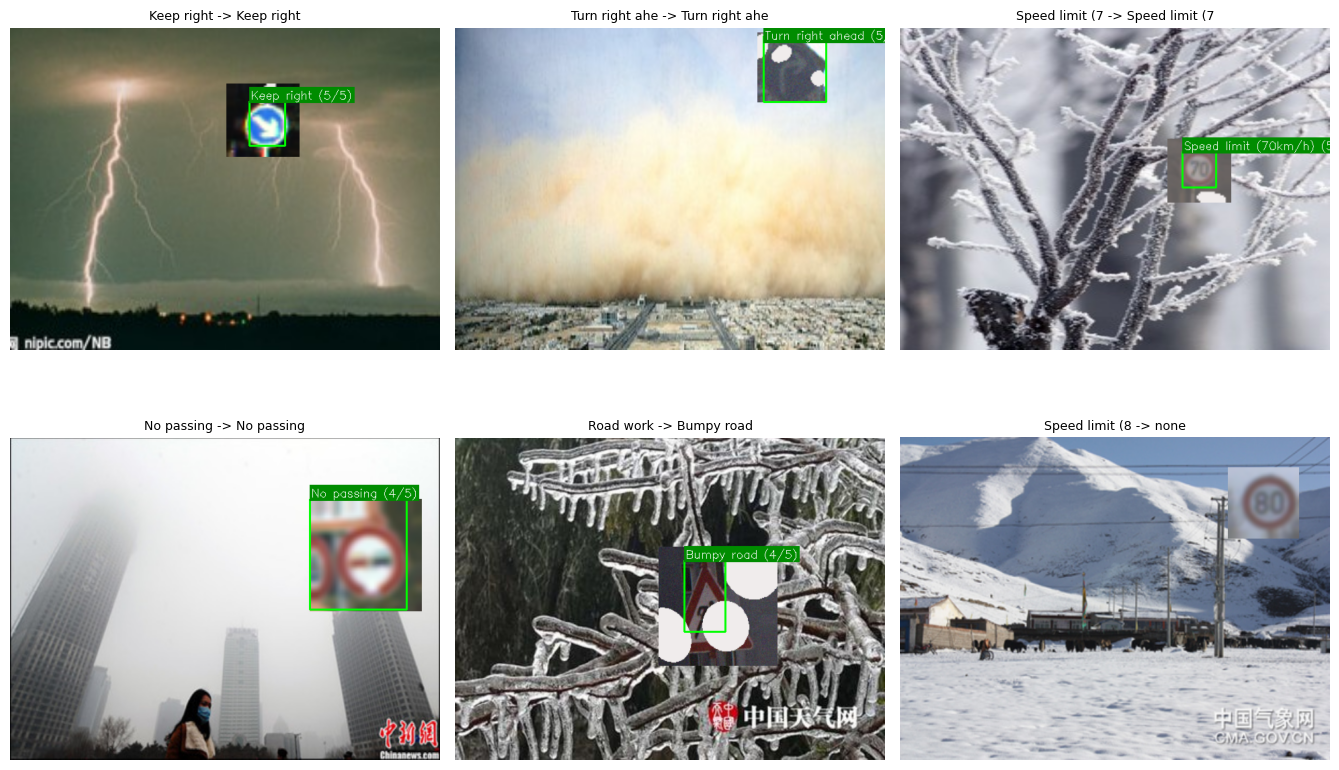

In [10]:
# CELL 10 - End-to-end test on synthetic scenes + write metrics.json
def make_test_scene(rs):
    bg = cv2.resize(cv2.imread(WEATHER_FILES[rs.randint(len(WEATHER_FILES))][0]), (640, 480))
    f, cid = val_items[rs.randint(len(val_items))]
    sign = augment_bgr(cv2.imread(f), rs)
    size = int(rs.randint(70, 200))
    x, y = int(rs.randint(0, 640 - size)), int(rs.randint(0, 480 - size))
    scene = bg.copy()
    scene[y:y + size, x:x + size] = cv2.resize(sign, (size, size))
    return scene, cid, (x, y, size, size)


if NEED_TRAIN:
    rs_t = np.random.RandomState(123)
    found = correct = 0
    examples = []
    t0 = time.time()
    for i in range(N_E2E_TEST):
        scene, cid, gt = make_test_scene(rs_t)
        d = detect_signs(scene, only_largest=True)
        if d and box_iou(d[0]['box'], gt) > 0.3:
            found += 1
            correct += int(d[0]['label'] == cid)
        if i < 6:
            examples.append((analyze(scene, only_largest=True)[0],
                             '%s -> %s' % (sign_names[cid][:14], sign_names[d[0]['label']][:14] if d else 'none')))
    sec_per_img = (time.time() - t0) / N_E2E_TEST
    METRICS['end_to_end'] = {'n_scenes': N_E2E_TEST, 'sign_found': found / N_E2E_TEST,
                             'class_correct': correct / N_E2E_TEST, 'sec_per_image': sec_per_img}
    METRICS['config'] = {'n_orig_per_class': N_ORIG_PER_CLASS, 'n_aug_per_class': N_AUG_PER_CLASS,
                         'k_words': K_WORDS, 'n_trees': N_TREES, 'seed': SEED, 'opencv': cv2.__version__,
                         'trained_on': time.strftime('%Y-%m-%d %H:%M')}
    with open('metrics.json', 'w') as fh:
        json.dump(METRICS, fh, indent=2)
    print('End-to-end (%d synthetic scenes): sign found %.0f%% | correct class %.0f%% | %.2f s/image' % (
        N_E2E_TEST, 100 * found / N_E2E_TEST, 100 * correct / N_E2E_TEST, sec_per_img))
    print('(Signs pasted on photos: easier than real road scenes, so real-world accuracy can be lower.)')
    print('Saved: metrics.json')
    show([e[0] for e in examples], [e[1] for e in examples], cols=3, size=4.5)
else:
    METRICS = json.load(open('metrics.json'))
    print('Saved models restored -> end-to-end test skipped, stored metrics loaded from metrics.json.')

## Cell 11 - Backup to Google Drive
Copies all model files and `metrics.json` to `MyDrive/traffic_opencv`, so the next session can skip training.

In [11]:
# CELL 11 - Backup models + metrics to Google Drive
if USE_DRIVE and IN_COLAB:
    os.makedirs(DRIVE_DIR, exist_ok=True)
    for f in REQUIRED_FILES + OPTIONAL_FILES:
        if os.path.exists(f):
            shutil.copy(f, os.path.join(DRIVE_DIR, f))
            print('backed up', f)
    print('Backup folder:', DRIVE_DIR)
else:
    print('Drive backup skipped (USE_DRIVE is False or not running in Colab). Files are in the working folder.')

backed up sign_svm.xml
backed up sign_pre.npz
backed up weather_rf.xml
backed up weather_meta.json
backed up metrics.json
backed up weather_svm.xml
backed up weather_pre.npz
backed up weather_bovw.npy
Backup folder: /content/drive/MyDrive/traffic_opencv


## Cell 12 - Results dashboard
All accuracy numbers, charts and confusion matrices in one place, read from `metrics.json` (works without the datasets). Good for screenshots in the internship report.

 RESULTS SUMMARY
SIGN CLASSIFIER  (GTSRB, 43 classes + background, track-wise validation)
  validation images clean / stress : 3620 / 3620
  accuracy, clean                  : 90.41%
  accuracy, stress (augmented)     : 59.70%
  background wrongly called a sign : 4.46%
  sign wrongly called background   : 0.55%
  model: PCA 150 dims (73.6% variance) + RBF SVM, C=10

WEATHER CLASSIFIER  (11 classes, 1369 validation images)
  chosen model        : D  RF + SVM ensemble
  accuracy            : 79.33%
  balanced accuracy   : 78.23%
  top-3 accuracy      : 94.52%
  all candidates      : A 74.7% | B 77.6% | C 79.3% | D 79.3%

END-TO-END  (100 synthetic scenes)
  sign found          : 37%
  correct class       : 32%
  speed               : 0.37 s / image (CPU)


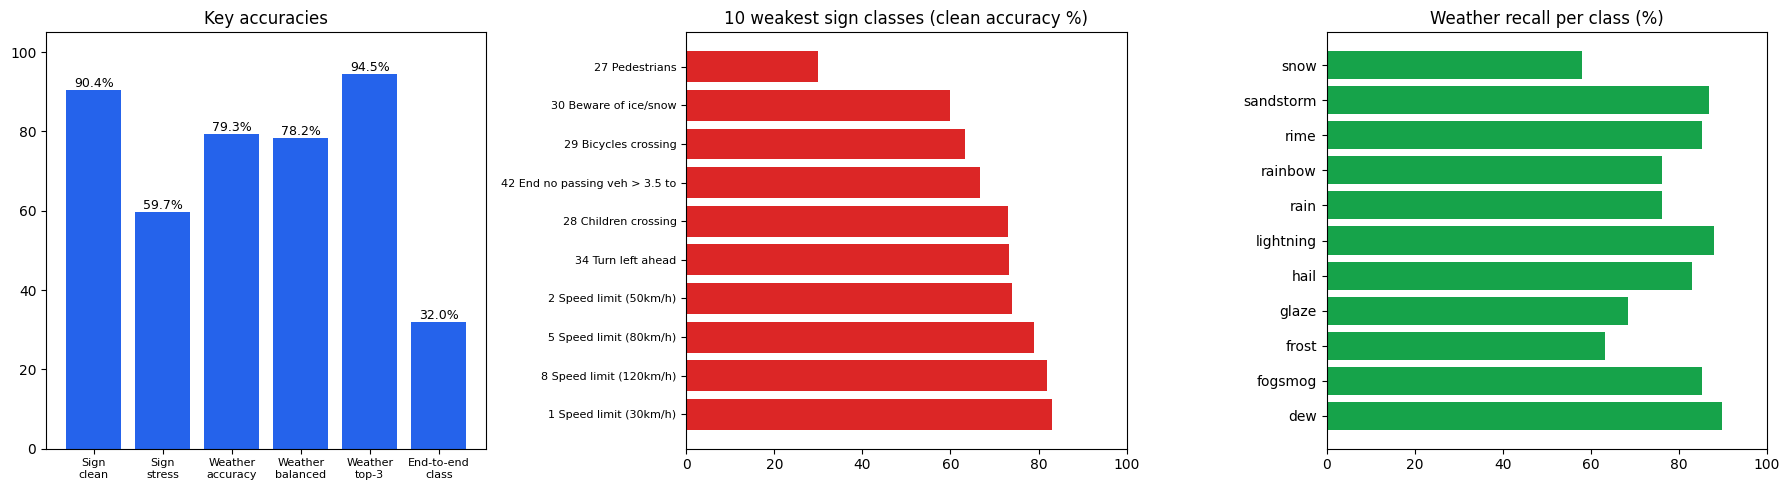

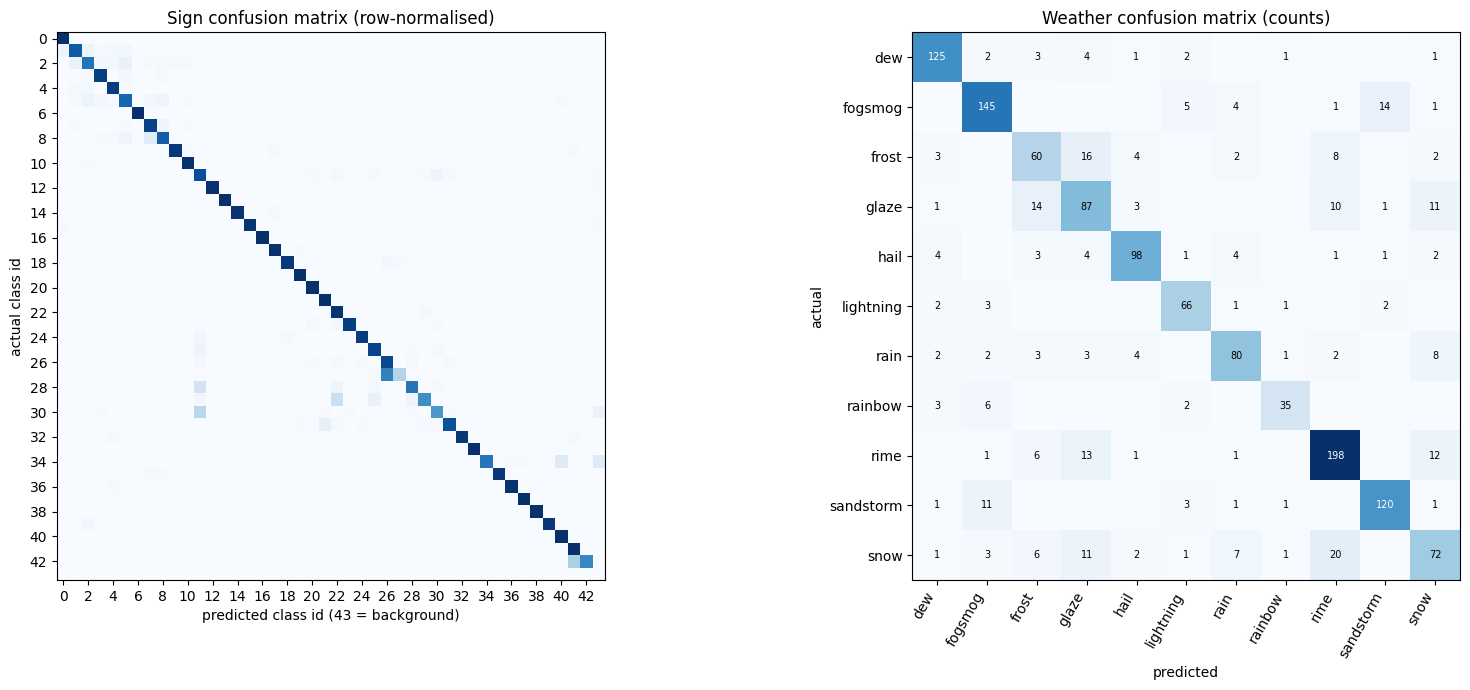

Most frequent sign confusions (actual -> predicted):
   41 x  Pedestrians  ->  Traffic signals
   25 x  Beware of ice/snow  ->  Right-of-way at intersection
   20 x  End no passing veh > 3.5 tons  ->  End of no passing
   18 x  Children crossing  ->  Right-of-way at intersection
   13 x  Bicycles crossing  ->  Bumpy road
   11 x  Turn left ahead  ->  background
   11 x  Turn left ahead  ->  Roundabout mandatory
   11 x  Speed limit (120km/h)  ->  Speed limit (100km/h)


In [12]:
# CELL 12 - Results dashboard (reads METRICS / metrics.json)
M = METRICS
S, Wt, E = M.get('sign'), M.get('weather'), M.get('end_to_end')
bar = '=' * 64
print(bar + '\n RESULTS SUMMARY\n' + bar)
if S:
    print('SIGN CLASSIFIER  (GTSRB, 43 classes + background, track-wise validation)')
    print('  validation images clean / stress : %d / %d' % (S['n_val_clean'], S['n_val_stress']))
    print('  accuracy, clean                  : %.2f%%' % (100 * S['clean_acc']))
    print('  accuracy, stress (augmented)     : %.2f%%' % (100 * S['stress_acc']))
    print('  background wrongly called a sign : %.2f%%' % (100 * S['bg_false_sign']))
    print('  sign wrongly called background   : %.2f%%' % (100 * S['sign_as_bg']))
    print('  model: PCA %d dims (%.1f%% variance) + RBF SVM, C=%g' % (S['pca_dims'], S['pca_variance_pct'], S['svm_C']))
if Wt:
    print('\nWEATHER CLASSIFIER  (%d classes, %d validation images)' % (len(Wt['classes']), Wt['n_val']))
    print('  chosen model        : %s' % Wt['chosen'])
    print('  accuracy            : %.2f%%' % (100 * Wt['accuracy']))
    print('  balanced accuracy   : %.2f%%' % (100 * Wt['balanced_accuracy']))
    print('  top-3 accuracy      : %.2f%%' % (100 * Wt['top3']))
    print('  all candidates      : ' + ' | '.join('%s %.1f%%' % (k[0], 100 * v['acc']) for k, v in Wt['comparison'].items()))
if E:
    print('\nEND-TO-END  (%d synthetic scenes)' % E['n_scenes'])
    print('  sign found          : %.0f%%' % (100 * E['sign_found']))
    print('  correct class       : %.0f%%' % (100 * E['class_correct']))
    print('  speed               : %.2f s / image (CPU)' % E['sec_per_image'])
print(bar)

if S and Wt:
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    labels = ['Sign\nclean', 'Sign\nstress', 'Weather\naccuracy', 'Weather\nbalanced', 'Weather\ntop-3']
    vals = [S['clean_acc'], S['stress_acc'], Wt['accuracy'], Wt['balanced_accuracy'], Wt['top3']]
    if E:
        labels += ['End-to-end\nclass']
        vals += [E['class_correct']]
    b = ax[0].bar(labels, [100 * v for v in vals], color='#2563EB')
    ax[0].bar_label(b, fmt='%.1f%%', fontsize=9)
    ax[0].set_ylim(0, 105)
    ax[0].set_title('Key accuracies')
    ax[0].tick_params(axis='x', labelsize=8)

    pc = sorted(((int(c), a) for c, a in S['per_class_acc'].items()), key=lambda t: t[1])[:10]
    ax[1].barh([('%d %s' % (c, sign_names[c]))[:30] for c, _ in pc][::-1], [100 * a for _, a in pc][::-1], color='#DC2626')
    ax[1].set_xlim(0, 100)
    ax[1].set_title('10 weakest sign classes (clean accuracy %)')
    ax[1].tick_params(axis='y', labelsize=8)

    wr = Wt['per_class_recall']
    ax[2].barh(list(wr.keys()), [100 * v for v in wr.values()], color='#16A34A')
    ax[2].set_xlim(0, 100)
    ax[2].set_title('Weather recall per class (%)')
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(1, 2, figsize=(17, 7))
    cm = np.array(S['confusion'], float)
    ax[0].imshow(cm / np.maximum(cm.sum(1, keepdims=True), 1), cmap='Blues', vmin=0, vmax=1)
    ax[0].set_xticks(range(0, 44, 2)); ax[0].set_yticks(range(0, 44, 2))
    ax[0].set_xlabel('predicted class id (43 = background)'); ax[0].set_ylabel('actual class id')
    ax[0].set_title('Sign confusion matrix (row-normalised)')
    cw = np.array(Wt['confusion'])
    ax[1].imshow(cw, cmap='Blues')
    ax[1].set_xticks(range(len(Wt['classes']))); ax[1].set_xticklabels(Wt['classes'], rotation=60, ha='right')
    ax[1].set_yticks(range(len(Wt['classes']))); ax[1].set_yticklabels(Wt['classes'])
    for i in range(cw.shape[0]):
        for j in range(cw.shape[1]):
            if cw[i, j]:
                ax[1].text(j, i, cw[i, j], ha='center', va='center', fontsize=7,
                           color='white' if cw[i, j] > cw.max() / 2 else 'black')
    ax[1].set_xlabel('predicted'); ax[1].set_ylabel('actual'); ax[1].set_title('Weather confusion matrix (counts)')
    plt.tight_layout()
    plt.show()

    off = [(cm[i, j], i, j) for i in range(44) for j in range(44) if i != j and cm[i, j] > 0]
    print('Most frequent sign confusions (actual -> predicted):')
    for n, i, j in sorted(off, reverse=True)[:8]:
        print('  %3d x  %s  ->  %s' % (n, sign_names[i], sign_names[j]))

## Cell 13 - Web UI
Upload a road photo. `share=True` gives a public link (new for every session, valid for about a week).

In [ ]:
# CELL 13 - Web UI (Gradio)
import gradio as gr


def ui_fn(pil_img, only_largest, min_agree):
    if pil_img is None:
        return None, None, 'Please upload an image first.'
    bgr = cv2.cvtColor(np.array(pil_img.convert('RGB')), cv2.COLOR_RGB2BGR)
    ann, mask_view, report = analyze(bgr, bool(only_largest), float(min_agree))
    return cv2.cvtColor(ann, cv2.COLOR_BGR2RGB), cv2.cvtColor(mask_view, cv2.COLOR_BGR2RGB), report


demo = gr.Interface(
    fn=ui_fn,
    inputs=[gr.Image(type='pil', label='Road image'),
            gr.Checkbox(value=True, label='Show only the largest sign'),
            gr.Slider(0.4, 1.0, value=0.6, step=0.2, label='Min agreement (how many of the 5 crops must give the same answer)')],
    outputs=[gr.Image(type='numpy', label='Detected sign'),
             gr.Image(type='numpy', label='Colour mask view'),
             gr.Textbox(label='Analysis report', lines=8)],
    title='OpenCV Traffic Sign + Weather Analyzer',
    description='OpenCV only: colour + shape finds the sign, HOG + SVM recognises it, hand-made features + RandomForest predict the weather.',
)
demo.launch(share=True)